In [ ]:
!pip -q install transformers torch gradio


             STUDENT FEEDBACK ANALYSIS SYSTEM

FEEDBACK ANALYSIS RESULTS
----------------------------------------------------------------------
   Student                                      Feedback Sentiment  Sentiment Score
 Student 1   The teacher explains concepts very clearly.  Positive            0.130
 Student 2  The classes are interesting and interactive.  Positive            0.500
 Student 3         I find the assignments too difficult.  Negative           -0.500
 Student 4             The teaching method is excellent.  Positive            1.000
 Student 5        The classroom environment is not good.  Negative           -0.350
 Student 6     The teacher is very helpful and friendly.  Positive            0.287
 Student 7                   There is too much homework.  Positive            0.200
 Student 8                 I really enjoyed this course.  Positive            0.500
 Student 9            The lectures are sometimes boring.  Negative           -1.000
Student 10 The c

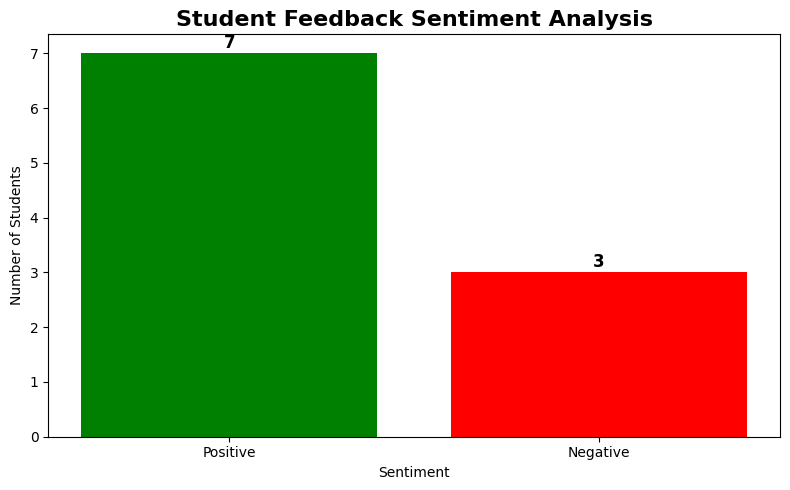

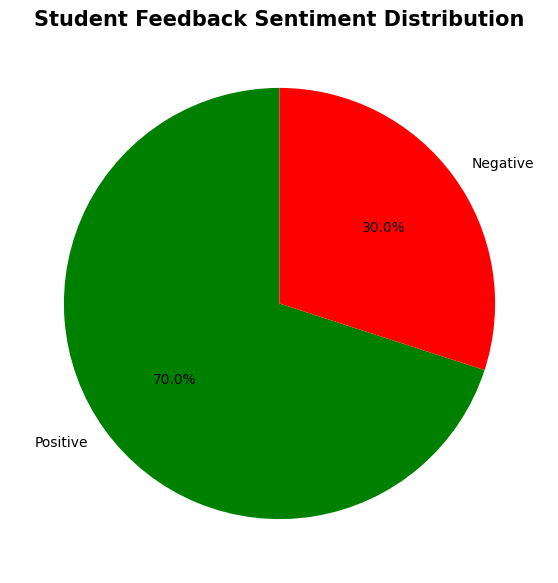

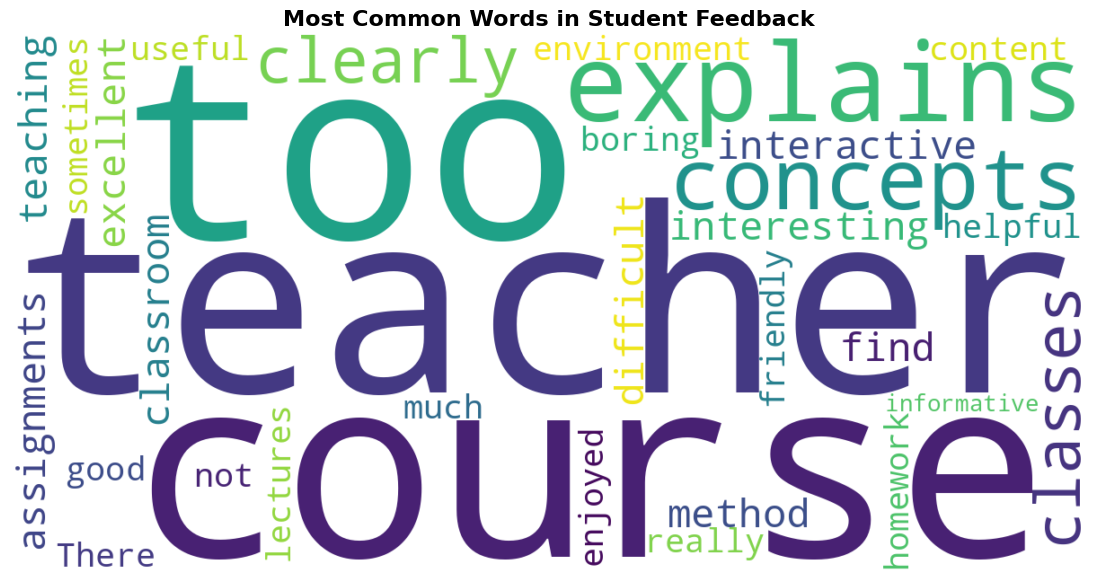



                    POSITIVE FEEDBACK
✓ The teacher explains concepts very clearly.
✓ The classes are interesting and interactive.
✓ The teaching method is excellent.
✓ The teacher is very helpful and friendly.
✓ There is too much homework.
✓ I really enjoyed this course.
✓ The course content is useful and informative.


                    NEGATIVE FEEDBACK
✗ I find the assignments too difficult.
✗ The classroom environment is not good.
✗ The lectures are sometimes boring.


                     OVERALL ANALYSIS
Overall Result: Students are generally satisfied with the course.


/tmp/ipykernel_519/3501053723.py:488: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(




              STARTING WEB APPLICATION
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://42eb5257cc0ec21c71.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [1]:
# ============================================================
# STUDENT FEEDBACK ANALYSIS APPLICATION
# Google Colab - Complete Single Cell Code
# ============================================================

# Install required libraries
!pip install -q pandas matplotlib seaborn textblob wordcloud gradio openpyxl

# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from textblob import TextBlob
from wordcloud import WordCloud
import gradio as gr
import re
import os

# ------------------------------------------------------------
# 1. SAMPLE STUDENT FEEDBACK DATA
# ------------------------------------------------------------

data = {
    "Student": [
        "Student 1", "Student 2", "Student 3", "Student 4",
        "Student 5", "Student 6", "Student 7", "Student 8",
        "Student 9", "Student 10"
    ],

    "Feedback": [
        "The teacher explains concepts very clearly.",
        "The classes are interesting and interactive.",
        "I find the assignments too difficult.",
        "The teaching method is excellent.",
        "The classroom environment is not good.",
        "The teacher is very helpful and friendly.",
        "There is too much homework.",
        "I really enjoyed this course.",
        "The lectures are sometimes boring.",
        "The course content is useful and informative."
    ]
}

df = pd.DataFrame(data)


# ------------------------------------------------------------
# 2. SENTIMENT ANALYSIS FUNCTIONS
# ------------------------------------------------------------

def get_sentiment(text):

    polarity = TextBlob(str(text)).sentiment.polarity

    if polarity > 0.1:
        return "Positive"

    elif polarity < -0.1:
        return "Negative"

    else:
        return "Neutral"


def get_sentiment_score(text):

    return round(
        TextBlob(str(text)).sentiment.polarity,
        3
    )


# Apply sentiment analysis
df["Sentiment"] = df["Feedback"].apply(get_sentiment)

df["Sentiment Score"] = df["Feedback"].apply(
    get_sentiment_score
)


# ------------------------------------------------------------
# 3. DISPLAY ANALYSIS RESULTS
# ------------------------------------------------------------

print("=" * 70)
print("             STUDENT FEEDBACK ANALYSIS SYSTEM")
print("=" * 70)

print("\nFEEDBACK ANALYSIS RESULTS")
print("-" * 70)

print(df.to_string(index=False))


# ------------------------------------------------------------
# 4. SENTIMENT SUMMARY
# ------------------------------------------------------------

sentiment_counts = df["Sentiment"].value_counts()

total_feedback = len(df)

positive_count = sentiment_counts.get("Positive", 0)
negative_count = sentiment_counts.get("Negative", 0)
neutral_count = sentiment_counts.get("Neutral", 0)

positive_percentage = (positive_count / total_feedback) * 100
negative_percentage = (negative_count / total_feedback) * 100
neutral_percentage = (neutral_count / total_feedback) * 100

print("\n")
print("=" * 70)
print("                    SENTIMENT SUMMARY")
print("=" * 70)

print(f"Total Feedback : {total_feedback}")
print(
    f"Positive       : {positive_count} "
    f"({positive_percentage:.1f}%)"
)
print(
    f"Negative       : {negative_count} "
    f"({negative_percentage:.1f}%)"
)
print(
    f"Neutral        : {neutral_count} "
    f"({neutral_percentage:.1f}%)"
)


# ------------------------------------------------------------
# 5. SENTIMENT BAR CHART
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

colors = {
    "Positive": "green",
    "Negative": "red",
    "Neutral": "gray"
}

bars = plt.bar(
    sentiment_counts.index,
    sentiment_counts.values,
    color=[
        colors.get(x, "blue")
        for x in sentiment_counts.index
    ]
)

plt.title(
    "Student Feedback Sentiment Analysis",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Sentiment")
plt.ylabel("Number of Students")

# Add values above bars
for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.1,
        str(int(height)),
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. SENTIMENT PIE CHART
# ------------------------------------------------------------

plt.figure(figsize=(7, 7))

plt.pie(
    sentiment_counts.values,
    labels=sentiment_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=[
        colors.get(x, "blue")
        for x in sentiment_counts.index
    ]
)

plt.title(
    "Student Feedback Sentiment Distribution",
    fontsize=15,
    fontweight="bold"
)

plt.show()


# ------------------------------------------------------------
# 7. WORD CLOUD
# ------------------------------------------------------------

all_feedback = " ".join(
    df["Feedback"].astype(str)
)

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    colormap="viridis",
    stopwords=set([
        "the",
        "is",
        "and",
        "are",
        "to",
        "of",
        "a",
        "this",
        "very",
        "I"
    ])
).generate(all_feedback)

plt.figure(figsize=(14, 7))

plt.imshow(
    wordcloud,
    interpolation="bilinear"
)

plt.axis("off")

plt.title(
    "Most Common Words in Student Feedback",
    fontsize=16,
    fontweight="bold"
)

plt.show()


# ------------------------------------------------------------
# 8. POSITIVE AND NEGATIVE FEEDBACK
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("                    POSITIVE FEEDBACK")
print("=" * 70)

positive_feedback = df[
    df["Sentiment"] == "Positive"
]

if len(positive_feedback) > 0:

    for feedback in positive_feedback["Feedback"]:

        print("✓", feedback)

else:

    print("No positive feedback found.")


print("\n")
print("=" * 70)
print("                    NEGATIVE FEEDBACK")
print("=" * 70)

negative_feedback = df[
    df["Sentiment"] == "Negative"
]

if len(negative_feedback) > 0:

    for feedback in negative_feedback["Feedback"]:

        print("✗", feedback)

else:

    print("No negative feedback found.")


# ------------------------------------------------------------
# 9. OVERALL FEEDBACK ANALYSIS
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("                     OVERALL ANALYSIS")
print("=" * 70)

if positive_percentage > negative_percentage:

    print(
        "Overall Result: Students are generally satisfied "
        "with the course."
    )

elif negative_percentage > positive_percentage:

    print(
        "Overall Result: Students have expressed several "
        "concerns about the course."
    )

else:

    print(
        "Overall Result: Student opinions are mixed."
    )


# ------------------------------------------------------------
# 10. INTERACTIVE APPLICATION
# ------------------------------------------------------------

def analyze_student_feedback(feedback):

    # Check empty input
    if feedback is None or feedback.strip() == "":

        return (
            "No Feedback",
            0,
            "Please enter student feedback.",
            "⚠️"
        )

    # Get sentiment
    sentiment = get_sentiment(feedback)

    # Get score
    score = get_sentiment_score(feedback)

    # Generate explanation
    if sentiment == "Positive":

        message = (
            "The feedback expresses a positive opinion. "
            "The student appears satisfied with the course "
            "or teaching."
        )

        emoji = "😊"

    elif sentiment == "Negative":

        message = (
            "The feedback expresses a negative opinion. "
            "The teacher or institution may need to investigate "
            "the student's concerns."
        )

        emoji = "😞"

    else:

        message = (
            "The feedback is mostly neutral. "
            "The student does not express a strongly positive "
            "or negative opinion."
        )

        emoji = "😐"

    return (
        sentiment,
        score,
        message,
        emoji
    )


# ------------------------------------------------------------
# 11. CSV FILE ANALYSIS FUNCTION
# ------------------------------------------------------------

def analyze_csv(file):

    try:

        if file is None:

            return (
                "Please upload a CSV file.",
                None
            )

        # Read CSV
        uploaded_df = pd.read_csv(file.name)

        # Find feedback column
        possible_columns = [
            "Feedback",
            "feedback",
            "Comment",
            "comment",
            "Comments",
            "comments"
        ]

        feedback_column = None

        for column in possible_columns:

            if column in uploaded_df.columns:

                feedback_column = column
                break

        if feedback_column is None:

            return (
                "Error: CSV must contain a column named "
                "'Feedback'.",
                None
            )

        # Perform sentiment analysis
        uploaded_df["Sentiment"] = (
            uploaded_df[feedback_column]
            .astype(str)
            .apply(get_sentiment)
        )

        uploaded_df["Sentiment Score"] = (
            uploaded_df[feedback_column]
            .astype(str)
            .apply(get_sentiment_score)
        )

        # Calculate summary
        total = len(uploaded_df)

        positive = (
            uploaded_df["Sentiment"] == "Positive"
        ).sum()

        negative = (
            uploaded_df["Sentiment"] == "Negative"
        ).sum()

        neutral = (
            uploaded_df["Sentiment"] == "Neutral"
        ).sum()

        summary = f"""
STUDENT FEEDBACK ANALYSIS
=========================

Total Feedback : {total}

Positive       : {positive} ({positive/total*100:.1f}%)
Negative       : {negative} ({negative/total*100:.1f}%)
Neutral        : {neutral} ({neutral/total*100:.1f}%)

Analysis completed successfully.
"""

        return (
            summary,
            uploaded_df
        )

    except Exception as e:

        return (
            f"Error: {str(e)}",
            None
        )


# ------------------------------------------------------------
# 12. CREATE GRADIO APPLICATION
# ------------------------------------------------------------

with gr.Blocks(
    theme=gr.themes.Soft()
) as app:

    gr.Markdown(
        """
        # 🎓 Student Feedback Analysis System

        ### Analyze student feedback using Sentiment Analysis

        This application classifies student feedback into:

        - 😊 **Positive**
        - 😐 **Neutral**
        - 😞 **Negative**

        Enter individual feedback below or upload a CSV file
        containing multiple student feedback records.
        """
    )


    # --------------------------------------------------------
    # Individual Feedback Section
    # --------------------------------------------------------

    gr.Markdown("## 📝 Analyze Individual Feedback")

    with gr.Row():

        with gr.Column():

            feedback_input = gr.Textbox(
                label="Student Feedback",
                placeholder=(
                    "Example: The teacher explains "
                    "everything very clearly."
                ),
                lines=6
            )

            analyze_button = gr.Button(
                "🔍 Analyze Feedback",
                variant="primary"
            )


        with gr.Column():

            sentiment_output = gr.Textbox(
                label="Sentiment"
            )

            score_output = gr.Number(
                label="Sentiment Score"
            )

            message_output = gr.Textbox(
                label="Analysis"
            )

            emoji_output = gr.Textbox(
                label="Result"
            )


    analyze_button.click(
        fn=analyze_student_feedback,
        inputs=feedback_input,
        outputs=[
            sentiment_output,
            score_output,
            message_output,
            emoji_output
        ]
    )


    # --------------------------------------------------------
    # CSV Upload Section
    # --------------------------------------------------------

    gr.Markdown("---")

    gr.Markdown(
        """
        ## 📂 Analyze Multiple Student Feedback

        Upload a CSV file with a column named **Feedback**.

        Example:

        `Feedback`

        `The teacher is very helpful.`

        `The assignments are too difficult.`

        `The course is interesting.`
        """
    )

    csv_input = gr.File(
        label="Upload CSV File",
        file_types=[".csv"]
    )

    csv_button = gr.Button(
        "📊 Analyze CSV",
        variant="primary"
    )

    csv_summary = gr.Textbox(
        label="Analysis Summary",
        lines=10
    )

    csv_results = gr.Dataframe(
        label="Detailed Results"
    )

    csv_button.click(
        fn=analyze_csv,
        inputs=csv_input,
        outputs=[
            csv_summary,
            csv_results
        ]
    )


    # --------------------------------------------------------
    # Example Feedback
    # --------------------------------------------------------

    gr.Markdown("---")

    gr.Markdown(
        """
        ## 💡 Example Feedback

        **Positive:**
        > The teacher is excellent and explains every topic clearly.

        **Negative:**
        > The assignments are too difficult and the classes are boring.

        **Neutral:**
        > The course covers programming and database concepts.
        """
    )


# ------------------------------------------------------------
# 13. LAUNCH APPLICATION
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("              STARTING WEB APPLICATION")
print("=" * 70)

app.launch(share=True)
